# Collecting data


In [1]:
import pandas as pd, time,requests

/Users/rounaksambhwani/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
def get_text(inverted_index):
    words = {}                                
    for word, positions in inverted_index.items():
        for p in positions:
            words[p] = word
    text = ""
    for i in sorted(words):                    
        text += words[i] + " "
    return text.strip()

In [3]:
def paper_of_one_field(field_id, label, how_many):
    url = "https://api.openalex.org/works"
    papers = []
    page = 1

    while len(papers) < how_many:
        params = {
            "filter": f"primary_topic.field.id:{field_id},has_abstract:true,type:article,language:en",
            "sample": how_many,      
            "seed": 42,               
            "per-page": 100,
            "page": page,
        }
        data = requests.get(url, params=params).json()
        results = data.get("results", [])

        if len(results) == 0:                   
            break

        for paper in results:
            if paper["abstract_inverted_index"]:     
                papers.append({
                    "title": paper["title"],
                    "abstract": get_text(paper["abstract_inverted_index"]),
                    "label": label,
                })
        page += 1

    return pd.DataFrame(papers[:how_many])

In [4]:
science1 = paper_of_one_field(16, "Science", 350)           # 16 is the label of Chemistry
science2 = paper_of_one_field(31, "Science", 350)           # 31 is the labe of Physics
science3 = paper_of_one_field(13, "Science", 350)           # 13 is the label of Biochem/Genetics
business = paper_of_one_field(14, "Business", 1000)
social1  = paper_of_one_field(33, "Social Science", 500)    
social2  = paper_of_one_field(32, "Social Science", 500) 

In [5]:
df = pd.concat([science1, science2, science3, business, social1, social2], ignore_index=True)
print(df["label"].value_counts())

label
Science           1050
Business          1000
Social Science    1000
Name: count, dtype: int64


In [6]:
df.head()

,title,abstract,label
0,Laboratory measurements of water vapour contin...,Abstract In spite of decades of extensive stud...,Science
1,Propene oligomerization on H-mordenite: Hydrog...,The oligomerization of propene on H-mordenite ...,Science
2,Synthesis and MS Analysis of Thiazolium and Py...,Sensitivity of ESI-MS analysis of crude PNAs i...,Science
3,Flow system for the automatic screening of the...,"In this work, an automated flow-based procedur...",Science
4,Cover Feature: Experimental and Theoretical St...,Only products resulting from [4+2] cycloadditi...,Science


# making the order random

In [7]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.head(10)

,title,abstract,label
0,On the functioning of prototypes of the adapti...,In the face of growing competition in the glob...,Business
1,Evaluation of Critical Thinking Elements: A Qu...,Critical thinking skills are essential in the ...,Social Science
2,"A broad, multi-faceted view of healthcare indu...",The U.S. Healthcare industry is arguably under...,Business
3,Visible-light-enabled stereoselective synthesi...,a scale-up experiment and elaborations to acce...,Science
4,Nuances of COVID-19 and Psychosocial Work Envi...,BACKGROUND: The global spread of COVID-19 make...,Social Science
5,Bridging the Gap between Transfer Pricing and ...,The authors examine the evolving interplay bet...,Business
6,A Nepali Translation of Brief Infant Sleep Que...,Background: Sleep problems are common in child...,Social Science
7,Biophysical and Pharmacological Characterizati...,Hair cell calcium channels regulate membrane e...,Science
8,Research on Spatial Coupling of the Urban Plan...,"In this paper, based on the reality and the go...",Social Science
9,Mapping the Active Membership Base of Corporat...,Researching socially responsible companies (CS...,Business


In [8]:
df.to_csv("raw_dataset.csv", index=False)

# Data cleaning


In [9]:
#first checking the number of missing abstracts
n_missing = df["abstract"].isna().sum()
print("Missing abstracts:", n_missing)


Missing abstracts: 0


In [10]:
#second looking for duplicate abstracts 
n_dup = df.duplicated(subset="abstract").sum()
print("Duplicate abstracts:", n_dup)

Duplicate abstracts: 30


# I am adding a feature to count the number of words in my dataset (its like tokenisation but we will do it later) here we are just trying to get the avg word count

In [11]:
df["word_count"] = df["abstract"].fillna("").str.split().str.len()

In [12]:
df["word_count"].quantile([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.95])

0.01      3.49
0.05     22.00
0.10     41.90
0.25     91.00
0.50    150.00
0.75    203.00
0.95    315.55
Name: word_count, dtype: float64

# okay so we had 0 missing abstracts 30 duplicates and in genral we have 150 words per abstract 
# so I removed those 30 abstracts and took only those abstracts which had more than 30 words 

In [13]:
df = df.drop_duplicates(subset="abstract")
df["word_count"] = df["abstract"].str.split().str.len()
df = df[df["word_count"] >= 30]

In [14]:
df["label"].value_counts()

label
Science           960
Business          945
Social Science    913
Name: count, dtype: int64

# now text preprocessing
# 1.converted everything into lowecase
# 2.Removing HTML tags or URLS if any
# 3.Removing Punctuations
# 4.Correcting spellings
# 5.Removing Stop Words from extract
# (I have taken many codes from Stack Overflow)

In [15]:
df["text"] = df["abstract"]

In [16]:
#1.
df["text"] = df["text"].str.lower()

In [17]:
#2.
import re,html
df["text"] = df["text"].apply(html.unescape)                    
df["text"] = df["text"].str.replace(r"<.*?>", " ", regex=True)  
df["text"] = df["text"].str.replace(r"http\S+|www\.\S+", " ", regex=True)

In [18]:
#3.
df["text"] = df["text"].str.replace(r"[^\w\s]", " ", regex=True)   # remove punctuation
df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()   # fix extra spaces

In [19]:
pip install textblob 

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [20]:
from textblob import TextBlob

for original in df["text"].head(5):
    fixed = str(TextBlob(original).correct())
    changed = [(a, b) for a, b in zip(original.split(), fixed.split()) if a != b]
    print(len(changed), "words changed:", changed[:15])
    print()

15 words changed: [('mentoring', 'entering'), ('ussr', 'user'), ('emphasizes', 'emphasized'), ('ussr', 'user'), ('cpsu', 'case'), ('initiators', 'initiator'), ('organizers', 'organizer'), ('adaptive', 'captive'), ('caring', 'daring'), ('motivated', 'motivate'), ('socio', 'soil'), ('ussr', 'user'), ('formalized', 'normalized'), ('functioning', 'sanctioning'), ('networks', 'network')]

16 words changed: [('skills', 'skill'), ('21st', 'must'), ('4cs', 'was'), ('learners', 'earners'), ('argumentation', 'argumentative'), ('9th', 'th'), ('skills', 'skill'), ('sampling', 'smiling'), ('nvivo', 'naive'), ('facilitator', 'facilitate'), ('pdf', 'of'), ('qualitative', 'quantitative'), ('skills', 'skill'), ('skills', 'skill'), ('critically', 'clinically')]

0 words changed: []

1 words changed: [('amino', 'among')]

24 words changed: [('covid', 'could'), ('pakistan', 'parisian'), ('lag', 'law'), ('pandemic', 'anaemic'), ('mediating', 'meditating'), ('eustress', 'distress'), ('wellbeing', 'welling')

# here we can see that n1 is changed to no and g1 to go which is completly changing the meaning of these abstracts so we will not apply spell correction

In [21]:
df["text"] = df["abstract"]

# Step 1: lowercase
df["text"] = df["text"].str.lower()

# Step 2: remove HTML
df["text"] = df["text"].apply(html.unescape)
df["text"] = df["text"].str.replace(r"<.*?>", " ", regex=True)

# Step 3: remove URLs
df["text"] = df["text"].str.replace(r"http\S+|www\.\S+", " ", regex=True)

# Step 4: remove punctuation
df["text"] = df["text"].str.replace(r"[^\w\s]", " ", regex=True)
df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()

In [22]:
#5.
import nltk
from nltk.corpus import stopwords
nltk.download("stopwords")
stop_words = set(stopwords.words("english"))

cleaned = []
for text in df["text"]:
    words = text.split()
    kept = [w for w in words if w not in stop_words]
    cleaned.append(" ".join(kept))

df["clean_abstract"] = cleaned

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/rounaksambhwani/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# now we move to Tokenization(1) and Lemmatization(2)
# (I have not used Stemming instead I have used Lemmatization for my words to make sense) 

In [23]:
nltk.download("punkt")
nltk.download("punkt_tab")     
nltk.download("wordnet")

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/rounaksambhwani/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/rounaksambhwani/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/rounaksambhwani/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [24]:
#1.Tokenization 
from nltk.tokenize import word_tokenize

df["tokens"] = df["clean_abstract"].apply(word_tokenize)
df["tokens"][0][:15]

['face',
 'growing',
 'competition',
 'global',
 'economy',
 'objective',
 'necessity',
 'business',
 'provision',
 'high',
 'speed',
 'changes',
 'agile',
 'methodology',
 'become']

In [25]:
#2.Lemmatization
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

all_lemmas = []
for tokens in df["tokens"]:
    lemmas = [lemmatizer.lemmatize(w) for w in tokens]
    all_lemmas.append(lemmas)

df["lemmas"] = all_lemmas
df["lemmas"][0][:15]

['face',
 'growing',
 'competition',
 'global',
 'economy',
 'objective',
 'necessity',
 'business',
 'provision',
 'high',
 'speed',
 'change',
 'agile',
 'methodology',
 'become']

In [26]:
df["final_text"] = df["lemmas"].apply(lambda x: " ".join(x))
print(df["clean_abstract"][0][:200])
print(df["final_text"][0][:200])

face growing competition global economy objective necessity business provision high speed changes agile methodology become tool fast flexible development new products services interest agile model fol
face growing competition global economy objective necessity business provision high speed change agile methodology become tool fast flexible development new product service interest agile model follow


# Now applying Train-Test Split and TF-IDF to form these words into vectors

In [27]:
#Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["final_text"], df["label"], test_size=0.2, stratify=df["label"], random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))

(2254,) (564,)
label
Science           0.340728
Business          0.335404
Social Science    0.323869
Name: proportion, dtype: float64


In [28]:
#Applying TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3)
X_train_tfidf = tfidf.fit_transform(X_train)    # learns vocabulary from train only
X_test_tfidf = tfidf.transform(X_test)          # applies it to test

print(X_train_tfidf.shape, X_test_tfidf.shape)

(2254, 5000) (564, 5000)


# Modelling
# Now in Modelling I am using 6 baseline models
# 1.Logistic Regression
# 2.Decision Tree Classifier
# 3.Naive Bayes
# 4.KNN
# 5.SVM 
# 6.Random Forest

In [29]:
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []   
predictions = {}   

In [30]:
#1.
from sklearn.linear_model import LogisticRegression


lr = LogisticRegression(max_iter=1000, random_state=42)


start = time.time()
lr.fit(X_train_tfidf, y_train)
lr_time = time.time() - start


y_pred_lr = lr.predict(X_test_tfidf)
predictions["Logistic Regression"] = y_pred_lr



In [31]:
acc  = accuracy_score(y_test, y_pred_lr)
prec = precision_score(y_test, y_pred_lr, average="macro")
rec  = recall_score(y_test, y_pred_lr, average="macro")
f1   = f1_score(y_test, y_pred_lr, average="macro")

results.append({"Model": "Logistic Regression", "Accuracy": acc, "Precision": prec,
                "Recall": rec, "F1": f1, "Train time (s)": lr_time})

print("Accuracy :", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall   :", round(rec, 4))
print("F1       :", round(f1, 4))
print("Time     :", round(lr_time, 2), "s")

Accuracy : 0.8901
Precision: 0.8888
Recall   : 0.8892
F1       : 0.8889
Time     : 0.06 s


In [32]:
print(y_pred_lr[:5])
print(y_test.values[:5])

['Social Science' 'Business' 'Social Science' 'Business' 'Science']
['Social Science' 'Business' 'Social Science' 'Business' 'Science']


In [33]:
#2
from sklearn.tree import DecisionTreeClassifier


dt = DecisionTreeClassifier(random_state=42)

start = time.time()
dt.fit(X_train_tfidf, y_train)
dt_time = time.time() - start


y_pred_dt = dt.predict(X_test_tfidf)
predictions["Decision Tree"] = y_pred_dt

In [34]:
acc  = accuracy_score(y_test, y_pred_dt)
prec = precision_score(y_test, y_pred_dt, average="macro")
rec  = recall_score(y_test, y_pred_dt, average="macro")
f1   = f1_score(y_test, y_pred_dt, average="macro")

results.append({"Model": "Decision Tree", "Accuracy": acc, "Precision": prec,
                "Recall": rec, "F1": f1, "Train time (s)": dt_time})

print("Accuracy :", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall   :", round(rec, 4))
print("F1       :", round(f1, 4))
print("Time     :", round(dt_time, 2), "s")

Accuracy : 0.7305
Precision: 0.7306
Recall   : 0.7294
F1       : 0.7299
Time     : 0.21 s


In [35]:
print("Train accuracy:", round(dt.score(X_train_tfidf, y_train), 4))
print("Test accuracy :", round(dt.score(X_test_tfidf, y_test), 4))
print("Tree depth    :", dt.get_depth())

Train accuracy: 0.9996
Test accuracy : 0.7305
Tree depth    : 101


In [36]:
#so it is clear that Decision Tress is leading to overfitting

In [37]:
#3.
from sklearn.naive_bayes import MultinomialNB


nb = MultinomialNB()


start = time.time()
nb.fit(X_train_tfidf, y_train)
nb_time = time.time() - start


y_pred_nb = nb.predict(X_test_tfidf)
predictions["Naive Bayes"] = y_pred_nb

In [38]:
acc  = accuracy_score(y_test, y_pred_nb)
prec = precision_score(y_test, y_pred_nb, average="macro")
rec  = recall_score(y_test, y_pred_nb, average="macro")
f1   = f1_score(y_test, y_pred_nb, average="macro")

results.append({"Model": "Naive Bayes", "Accuracy": acc, "Precision": prec,
                "Recall": rec, "F1": f1, "Train time (s)": nb_time})

print("Accuracy :", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall   :", round(rec, 4))
print("F1       :", round(f1, 4))
print("Time     :", round(nb_time, 2), "s")

print("Train accuracy:", round(nb.score(X_train_tfidf, y_train), 4))
print("Test accuracy :", round(nb.score(X_test_tfidf, y_test), 4))

Accuracy : 0.8812
Precision: 0.8826
Recall   : 0.8799
F1       : 0.8803
Time     : 0.0 s
Train accuracy: 0.9401
Test accuracy : 0.8812


In [39]:
#4.
from sklearn.neighbors import KNeighborsClassifier


knn = KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute")

start = time.time()
knn.fit(X_train_tfidf, y_train)
knn_time = time.time() - start

start = time.time()
y_pred_knn = knn.predict(X_test_tfidf)
knn_pred_time = time.time() - start
predictions["kNN"] = y_pred_knn

In [40]:
acc  = accuracy_score(y_test, y_pred_knn)
prec = precision_score(y_test, y_pred_knn, average="macro")
rec  = recall_score(y_test, y_pred_knn, average="macro")
f1   = f1_score(y_test, y_pred_knn, average="macro")

results.append({"Model": "kNN", "Accuracy": acc, "Precision": prec,
                "Recall": rec, "F1": f1, "Train time (s)": knn_time})

print("Accuracy :", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall   :", round(rec, 4))
print("F1       :", round(f1, 4))
print("Train time  :", round(knn_time, 2), "s")
print("Predict time:", round(knn_pred_time, 2), "s")

print("Train accuracy:", round(knn.score(X_train_tfidf, y_train), 4))
print("Test accuracy :", round(knn.score(X_test_tfidf, y_test), 4))

Accuracy : 0.8457
Precision: 0.8491
Recall   : 0.8441
F1       : 0.8441
Train time  : 0.0 s
Predict time: 0.03 s
Train accuracy: 0.902
Test accuracy : 0.8457


In [41]:
#5.
from sklearn.svm import LinearSVC

svm = LinearSVC(random_state=42)

start = time.time()
svm.fit(X_train_tfidf, y_train)
svm_time = time.time() - start

y_pred_svm = svm.predict(X_test_tfidf)
predictions["SVM"] = y_pred_svm

In [42]:
acc  = accuracy_score(y_test, y_pred_svm)
prec = precision_score(y_test, y_pred_svm, average="macro")
rec  = recall_score(y_test, y_pred_svm, average="macro")
f1   = f1_score(y_test, y_pred_svm, average="macro")

results.append({"Model": "SVM", "Accuracy": acc, "Precision": prec,
                "Recall": rec, "F1": f1, "Train time (s)": svm_time})

print("Accuracy :", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall   :", round(rec, 4))
print("F1       :", round(f1, 4))
print("Time     :", round(svm_time, 2), "s")

print("Train accuracy:", round(svm.score(X_train_tfidf, y_train), 4))
print("Test accuracy :", round(svm.score(X_test_tfidf, y_test), 4))

Accuracy : 0.8865
Precision: 0.885
Recall   : 0.8856
F1       : 0.8852
Time     : 0.02 s
Train accuracy: 0.9973
Test accuracy : 0.8865


In [43]:
#6.
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

start = time.time()
rf.fit(X_train_tfidf, y_train)
rf_time = time.time() - start

y_pred_rf = rf.predict(X_test_tfidf)
predictions["Random Forest"] = y_pred_rf

In [44]:
acc  = accuracy_score(y_test, y_pred_rf)
prec = precision_score(y_test, y_pred_rf, average="macro")
rec  = recall_score(y_test, y_pred_rf, average="macro")
f1   = f1_score(y_test, y_pred_rf, average="macro")

results.append({"Model": "Random Forest", "Accuracy": acc, "Precision": prec,
                "Recall": rec, "F1": f1, "Train time (s)": rf_time})

print("Accuracy :", round(acc, 4))
print("Precision:", round(prec, 4))
print("Recall   :", round(rec, 4))
print("F1       :", round(f1, 4))
print("Time     :", round(rf_time, 2), "s")

print("Train accuracy:", round(rf.score(X_train_tfidf, y_train), 4))
print("Test accuracy :", round(rf.score(X_test_tfidf, y_test), 4))

Accuracy : 0.8404
Precision: 0.8418
Recall   : 0.8396
F1       : 0.8404
Time     : 0.18 s
Train accuracy: 0.9996
Test accuracy : 0.8404


# Comapring Results


In [45]:
results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
print(results_df.round(4))
results_df.to_csv("baseline_results.csv", index=False)

                 Model  Accuracy  Precision  Recall      F1  Train time (s)
0  Logistic Regression    0.8901     0.8888  0.8892  0.8889          0.0554
1                  SVM    0.8865     0.8850  0.8856  0.8852          0.0207
2          Naive Bayes    0.8812     0.8826  0.8799  0.8803          0.0020
3                  kNN    0.8457     0.8491  0.8441  0.8441          0.0010
4        Random Forest    0.8404     0.8418  0.8396  0.8404          0.1789
5        Decision Tree    0.7305     0.7306  0.7294  0.7299          0.2071


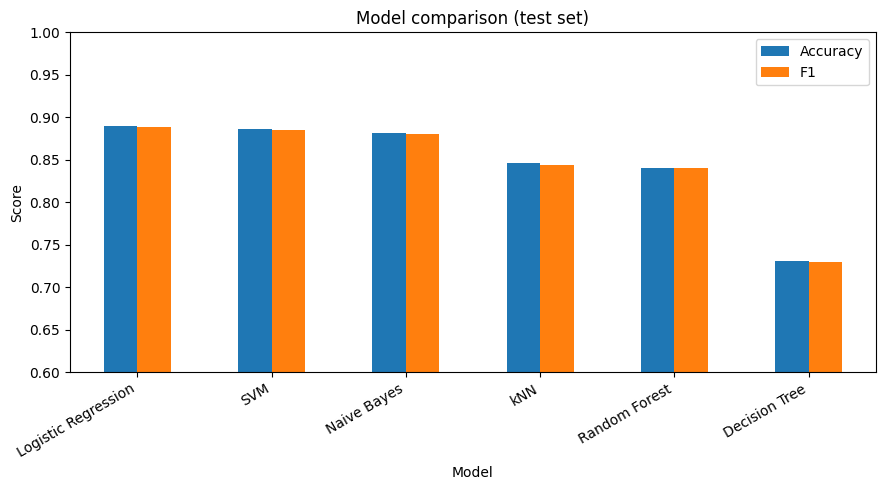

In [46]:
import matplotlib.pyplot as plt

ax = results_df.set_index("Model")[["Accuracy", "F1"]].plot(kind="bar", figsize=(9, 5))
ax.set_ylim(0.6, 1.0)                # start the axis at 0.6 so the differences are visible
ax.set_ylabel("Score")
ax.set_title("Model comparison (test set)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

In [47]:
models_fitted = {"Logistic Regression": lr, "Decision Tree": dt, "Naive Bayes": nb,
                 "kNN": knn, "SVM": svm, "Random Forest": rf}

gap = []
for name, m in models_fitted.items():
    tr = m.score(X_train_tfidf, y_train)
    te = m.score(X_test_tfidf, y_test)
    gap.append({"Model": name, "Train": tr, "Test": te, "Gap": tr - te})

gap_df = pd.DataFrame(gap).sort_values("Gap", ascending=False)
print(gap_df.round(4))

                 Model   Train    Test     Gap
1        Decision Tree  0.9996  0.7305  0.2691
5        Random Forest  0.9996  0.8404  0.1591
4                  SVM  0.9973  0.8865  0.1108
0  Logistic Regression  0.9694  0.8901  0.0793
2          Naive Bayes  0.9401  0.8812  0.0589
3                  kNN  0.9020  0.8457  0.0562


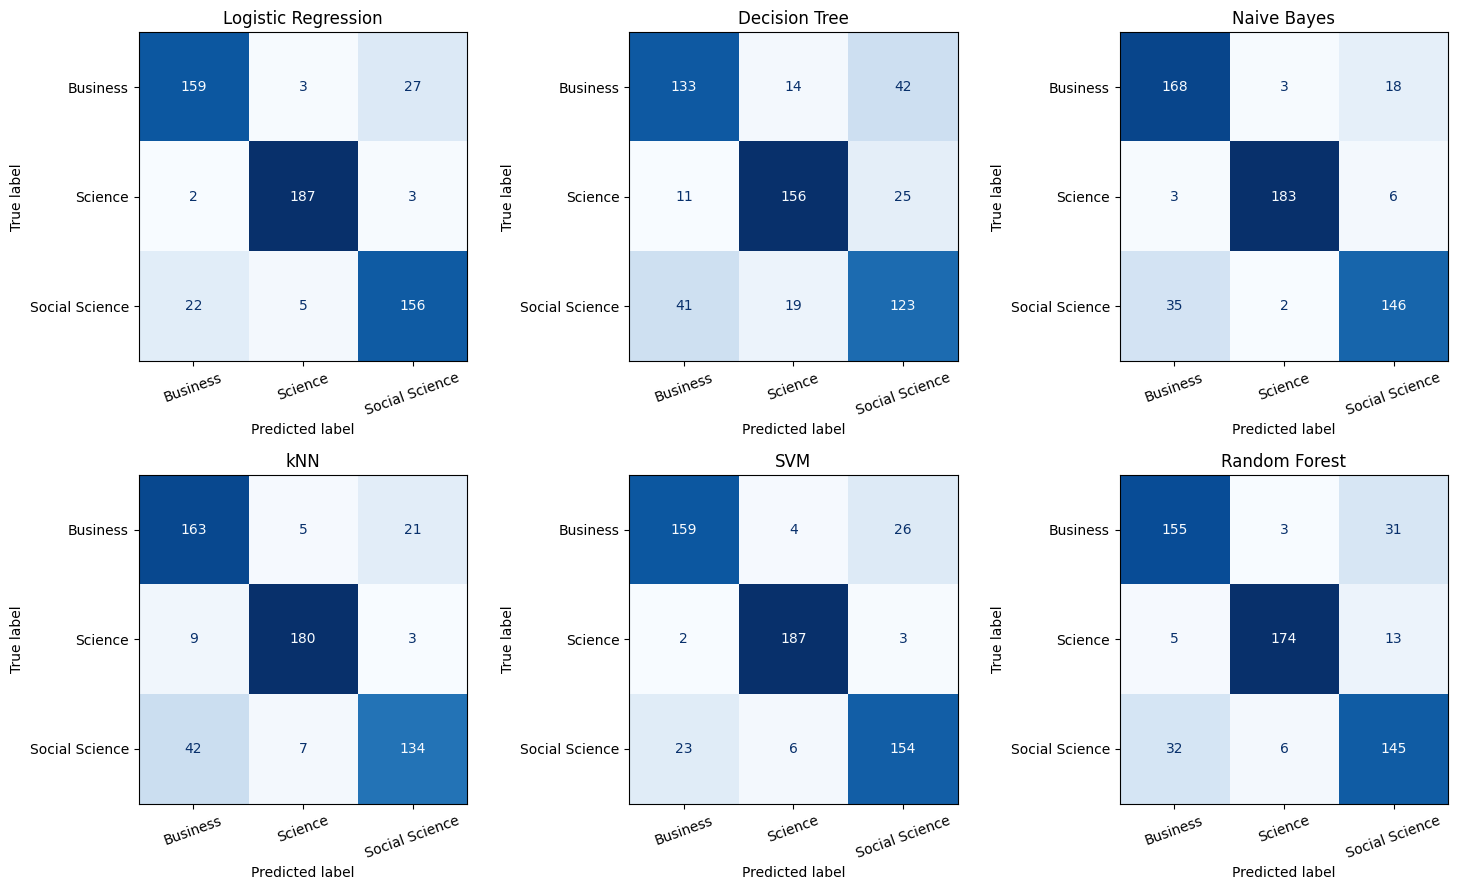

In [48]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

labels = ["Business", "Science", "Social Science"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=labels, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

In [49]:
import joblib, sklearn
joblib.dump(tfidf, "tfidf.joblib")
joblib.dump(lr, "model.joblib")
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


In [50]:
df[["title", "abstract", "label"]].to_csv("dataset.csv", index=False)

In [51]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3), LogisticRegression(max_iter=1000))
scores = cross_val_score(pipe, df["final_text"], df["label"], cv=5, scoring="f1_macro")
print(scores.round(4), scores.mean().round(4), "+/-", scores.std().round(4))

[0.9054 0.8927 0.8976 0.9048 0.8692] 0.8939 +/- 0.0132
